# Relevés du dynamomètre, essai du 2026-11-01

Trois enregistrements du dynamomètre posé sur la **corde du bas** (deux cordes Courant Bandit 11 mm
tendues « au mieux de façon similaire », tension sur Maestro). Portée 415,9 m, extrémités à 1 415,7 m
et 1 442,6 m, point bas à 1 360,9 m vers 182 m ([constats de l'essai](https://github.com/fuzoh/simu-tyro/issues/1#issuecomment-6695729571)).

Ce notebook ne modélise rien : il **isole les périodes en charge**, suit la **tension de pose** (ligne
de base) hors charge et mesure ce que chaque passage lui coûte. Les questions ouvertes sont renvoyées
aux tickets [#68](https://github.com/fuzoh/simu-tyro/issues/68) (faits de l'essai) et
[#69](https://github.com/fuzoh/simu-tyro/issues/69) (ce que l'essai valide).

Format des fichiers : 13 lignes d'en-tête, puis une valeur en **kN** par ligne, à **10 Hz**
(`Speed=10`), mode absolu (`Mode=ABS`). L'heure de début est celle de l'appareil ; rien ne garantit
encore qu'elle soit à l'heure locale, ni que l'en-tête `Pre=8` (secondes de pré-déclenchement) ne
décale pas l'origine de huit secondes. L'index temporel ci-dessous prend l'heure d'en-tête comme
premier échantillon, sans correction.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path.cwd()
FILES = sorted(HERE.glob("*.CSV"))
FS = 10.0  # Hz, d'après l'en-tête Speed=10

# Une couleur fixe par fichier, dans l'ordre chronologique.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, MUTED, GRID = "#1a1a19", "#6b6a62", "#e4e3dc"

plt.rcParams.update({
    "figure.figsize": (12, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "lines.linewidth": 1.2,
})
[f.name for f in FILES]

['16_03_43.CSV', '16_18_22.CSV', '16_50_30.CSV']

## Lecture

In [2]:
def read_log(path: Path) -> tuple[dict, pd.Series]:
    """Retourne (en-tête, tension en kN indexée par l'heure de l'appareil)."""
    lines = path.read_text(encoding="latin-1").splitlines()
    header = {"device": lines[0], "date": lines[1], "time": lines[2]}
    for line in lines[3:13]:
        key, _, value = line.partition("=")
        header[key] = value
    values = np.array([float(x) for x in lines[13:] if x.strip()])
    start = pd.to_datetime(f"{header['date']} {header['time']}", format="%d.%m.%y %H:%M:%S")
    index = start + pd.to_timedelta(np.arange(len(values)) / FS, unit="s")
    return header, pd.Series(values, index=index, name=path.stem)

logs: dict[str, pd.Series] = {}
rows = []
for path in FILES:
    header, s = read_log(path)
    logs[path.stem] = s
    rows.append({
        "fichier": path.name, "LogNo": header["LogNo"], "début": s.index[0].strftime("%H:%M:%S"),
        "fin": s.index[-1].strftime("%H:%M:%S"), "durée [s]": round(len(s) / FS),
        "Total (en-tête) [s]": header["Total"], "min [kN]": s.min(), "max [kN]": s.max(),
        "moyenne [kN]": round(s.mean(), 2),
    })
pd.DataFrame(rows)

,fichier,LogNo,début,fin,durée [s],Total (en-tête) [s],min [kN],max [kN],moyenne [kN]
0,16_03_43.CSV,030,16:03:43,16:08:17,275,274,1.33,2.16,1.72
1,16_18_22.CSV,031,16:18:22,16:50:29,1928,1928,1.02,2.38,1.67
2,16_50_30.CSV,032,16:50:30,16:56:55,386,386,1.05,2.09,1.28


`Total` de l'en-tête correspond au nombre d'échantillons divisé par 10 : la cadence de 10 Hz est
confirmée. Les trois fichiers restent toujours au-dessus du seuil d'arrêt (`Stop=0.80` kN) : les
enregistrements ont été démarrés et arrêtés à la main, pas par le déclencheur. Le deuxième se
termine à 16:50:29 et le troisième commence à 16:50:30 : c'est un seul enregistrement coupé en deux.

## Vue d'ensemble de l'après-midi

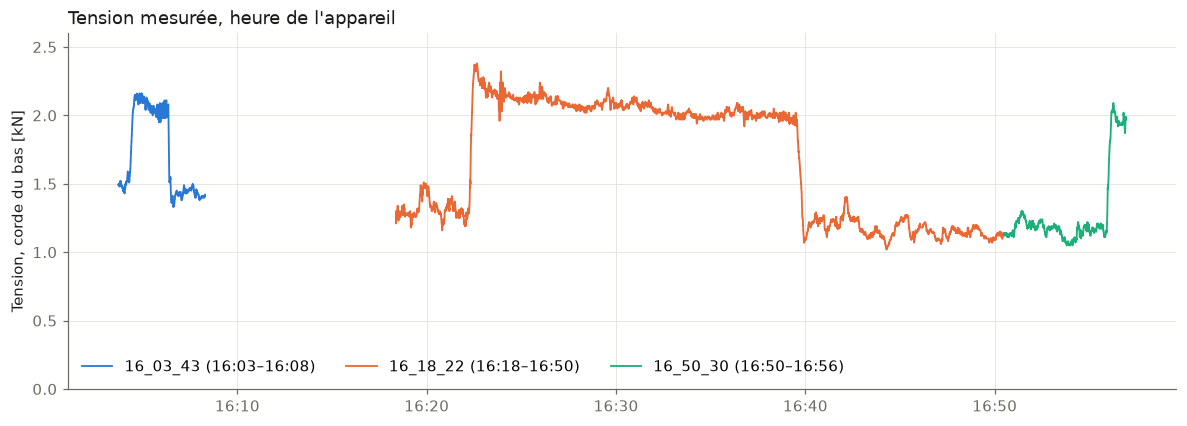

In [3]:
fig, ax = plt.subplots(figsize=(13, 4.2))
for color, (name, s) in zip(SERIES, logs.items()):
    ax.plot(s.index, s.values, color=color, label=f"{name} ({s.index[0]:%H:%M}–{s.index[-1]:%H:%M})")
ax.set_ylabel("Tension, corde du bas [kN]")
ax.set_ylim(0, 2.6)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_title("Tension mesurée, heure de l'appareil", loc="left", color=INK)
ax.legend(loc="lower left", ncol=3)
plt.show()

Trois choses se voient à l'œil nu :

- la tension est soit **hors charge** (1,0 à 1,5 kN), soit **en charge** (1,9 à 2,4 kN), avec des
  transitions de quelques secondes : chaque période en charge est un passager suspendu à la ligne ;
- les périodes en charge sont **longues** : environ 2 min, environ 17 min, et une dernière qui dure
  encore quand l'enregistrement s'arrête. Ce ne sont pas des descentes libres de quarante secondes ;
  cela colle avec des passagers arrêtés par le vent vers 60 % de la ligne, puis ramenés ;
- la **ligne de base descend** d'un enregistrement à l'autre (≈1,50 → 1,40 → 1,27 → 1,13 kN) et
  aucune retension n'est visible dans les fichiers : les trois retensions notées sur le terrain ont eu
  lieu hors enregistrement.

## Périodes en charge et ligne de base

Un échantillon est **en charge** quand il dépasse de plus de 0,3 kN le 10ᵉ percentile du fichier ;
les périodes en charge de moins de deux secondes sont ignorées, celles séparées de moins de dix
secondes fusionnées, et seules celles dont le pic dépasse d'au moins 0,5 kN la tension des vingt
secondes précédentes sont retenues comme passager suspendu (une sollicitation de +0,2 kN pendant
25 s à 16:19:42 est ainsi écartée). La **ligne de base** est la médiane glissante (une minute) des seuls
échantillons hors charge, interpolée pendant les charges.

In [4]:
EXCESS_KN, PEAK_KN, MIN_S, MERGE_S, BASE_WINDOW_S = 0.30, 0.50, 2, 10, 60

def loaded_mask(s: pd.Series) -> np.ndarray:
    above = (s.values - np.percentile(s.values, 10)) > EXCESS_KN
    edges = np.flatnonzero(np.diff(np.r_[False, above, False]))
    segs = [(a, b) for a, b in zip(edges[::2], edges[1::2]) if b - a >= MIN_S * FS]
    merged: list[tuple[int, int]] = []
    for a, b in segs:
        if merged and a - merged[-1][1] < MERGE_S * FS:
            merged[-1] = (merged[-1][0], b)
        else:
            merged.append((a, b))
    mask = np.zeros(len(s), dtype=bool)
    for a, b in merged:
        mask[a:b] = True
    return mask

def baseline(s: pd.Series, mask: np.ndarray) -> pd.Series:
    free = s.where(~mask)
    w = int(BASE_WINDOW_S * FS)
    return free.rolling(w, center=True, min_periods=w // 4).median().interpolate(limit_direction="both")

def loads(s: pd.Series, mask: np.ndarray, base: pd.Series) -> pd.DataFrame:
    edges = np.flatnonzero(np.diff(np.r_[False, mask, False]))
    out = []
    margin = int(20 * FS)
    for a, b in zip(edges[::2], edges[1::2]):
        seg = s.iloc[a:b]
        before = s.iloc[max(0, a - margin):a].median() if a > 0 else np.nan
        after = s.iloc[b:b + margin].median() if b < len(s) else np.nan
        truncated = b >= len(s)
        if seg.max() - before < PEAK_KN:
            continue  # sollicitation légère (quelqu'un qui s'appuie ?), pas un passager suspendu
        end = seg.iloc[-int(20 * FS):-int(10 * FS)] if len(seg) > 30 * FS else seg.iloc[-int(10 * FS):]
        out.append({
            "fichier": s.name, "début": seg.index[0], "fin": seg.index[-1],
            "durée [s]": round((b - a) / FS), "tronqué": truncated,
            "pic [kN]": seg.max(), "heure du pic": seg.idxmax(),
            "pic à [s]": round((seg.idxmax() - seg.index[0]).total_seconds(), 1),
            "avant décrochage [kN]": round(end.median(), 2),
            "base avant [kN]": round(before, 2), "base après [kN]": round(after, 2),
        })
    return pd.DataFrame(out)

masks = {name: loaded_mask(s) for name, s in logs.items()}
bases = {name: baseline(s, masks[name]) for name, s in logs.items()}
events = pd.concat([loads(s, masks[n], bases[n]) for n, s in logs.items()], ignore_index=True)
events["Δ base [kN]"] = (events["base après [kN]"] - events["base avant [kN]"]).round(2)
events["pic − base avant [kN]"] = (events["pic [kN]"] - events["base avant [kN]"]).round(2)
events

,fichier,début,fin,durée [s],tronqué,pic [kN],heure du pic,pic à [s],avant décrochage [kN],base avant [kN],base après [kN],Δ base [kN],pic − base avant [kN]
0,16_03_43,2026-11-01 16:04:22.200,2026-11-01 16:06:22.600,120,False,2.16,2026-11-01 16:04:40.800,18.6,2.05,1.52,1.40,-0.12,0.64
1,16_18_22,2026-11-01 16:22:16.500,2026-11-01 16:39:48.100,1052,False,2.38,2026-11-01 16:22:38.700,22.2,1.93,1.26,1.13,-0.13,1.12
2,16_50_30,2026-11-01 16:55:57.700,2026-11-01 16:56:55.900,58,True,2.09,2026-11-01 16:56:15.200,17.5,1.94,1.16,NaN,NaN,0.93


Une seule période en charge par fichier. S'il y a eu deux passages dans le premier enregistrement,
ils ne sont pas séparés par un retour à vide : rien dans la mesure ne permet de les distinguer.

Dans chaque période, la tension **monte en une vingtaine de secondes** jusqu'à un pic de 2,1 à 2,4 kN,
soit **0,65 à 1,1 kN au-dessus de la pose**, puis **décroît lentement** vers 1,95 kN avant une chute
franche de quelques secondes au décrochage. Le pic correspond au passager au plus près du point bas ;
la décroissance ensuite est cohérente avec un passager qui se rapproche d'un ancrage (ramené ou se
tirant), la chute avec sa sortie de la ligne. Chaque passage **coûte 0,1 à 0,15 kN** de tension de pose.

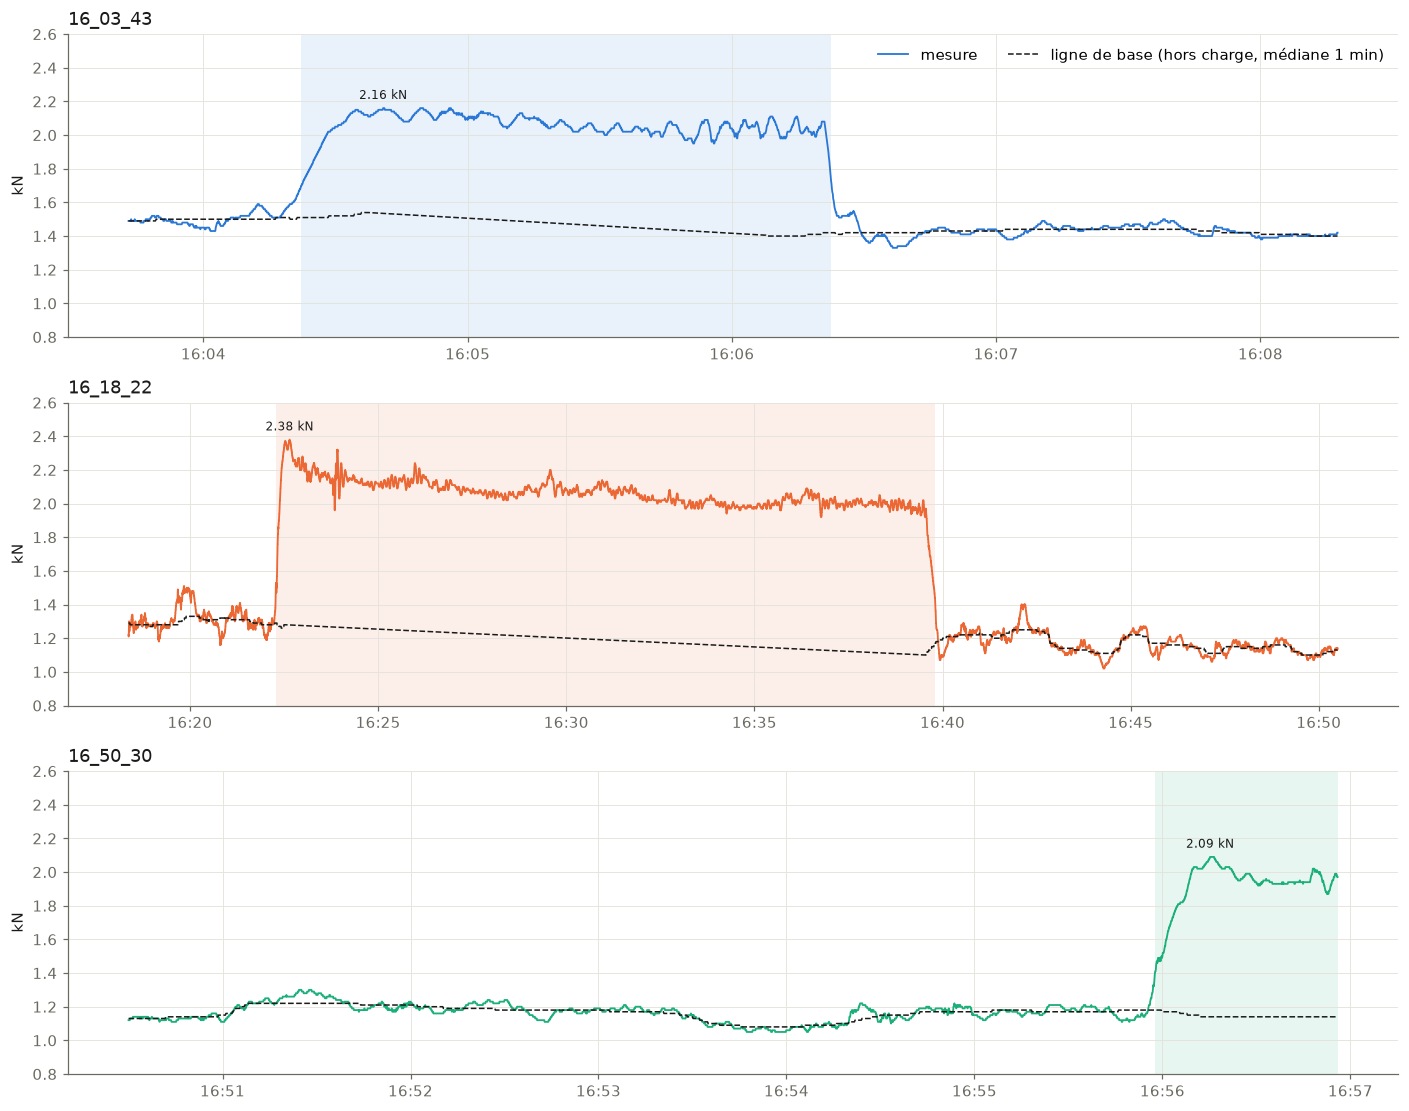

In [5]:
fig, axes = plt.subplots(len(logs), 1, figsize=(13, 3.4 * len(logs)), sharey=True)
for ax, color, (name, s) in zip(axes, SERIES, logs.items()):
    ax.plot(s.index, s.values, color=color, label="mesure")
    ax.plot(bases[name].index, bases[name].values, color=INK, linewidth=1, linestyle="--",
            label="ligne de base (hors charge, médiane 1 min)")
    for _, e in events[events["fichier"] == name].iterrows():
        ax.axvspan(e["début"], e["fin"], color=color, alpha=0.10, linewidth=0)
        ax.annotate(f"{e['pic [kN]']:.2f} kN", (e["heure du pic"], e["pic [kN]"]),
                    textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8, color=INK)
    ax.set_title(name, loc="left", color=INK)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_ylim(0.8, 2.6)
    ax.set_ylabel("kN")
axes[0].legend(loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

## Tension de pose au fil de l'après-midi

Hors charge, la tension de pose dérive aussi : elle baisse pendant les minutes qui suivent un
passage, puis se stabilise. Entre le premier et le deuxième fichier (16:08 à 16:18) elle passe de 1,40
à 1,27 kN sans qu'on sache ce qui s'est passé : c'est l'objet de la chronologie demandée dans
[#68](https://github.com/fuzoh/simu-tyro/issues/68).

In [6]:
rows = []
for name, s in logs.items():
    free = s[~masks[name]]
    rows.append({
        "fichier": name,
        "hors charge au début [kN]": round(free.iloc[:int(30 * FS)].median(), 2),
        "hors charge à la fin [kN]": round(free.iloc[-int(30 * FS):].median(), 2),
        "min hors charge [kN]": round(free.min(), 2),
        "durée hors charge [s]": round(len(free) / FS),
    })
pd.DataFrame(rows)

,fichier,hors charge au début [kN],hors charge à la fin [kN],min hors charge [kN],durée hors charge [s]
0,16_03_43,1.49,1.40,1.33,154
1,16_18_22,1.29,1.13,1.02,851
2,16_50_30,1.13,1.18,1.05,328


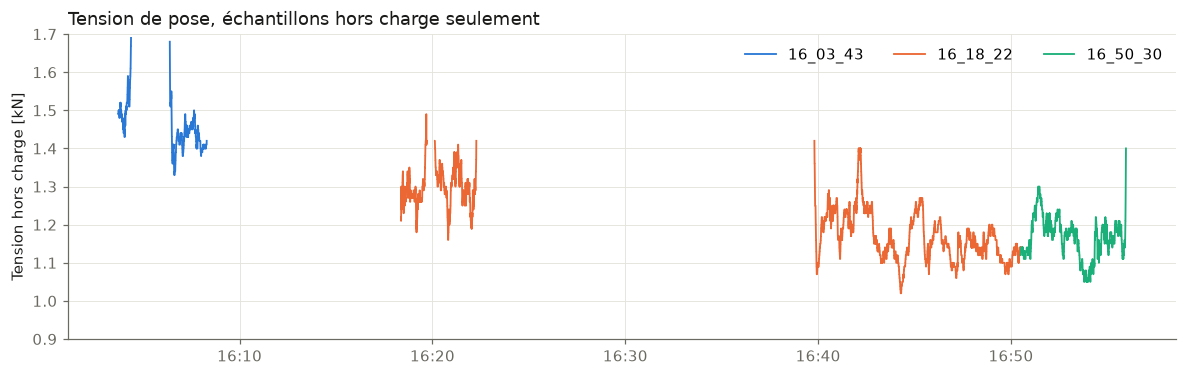

In [7]:
fig, ax = plt.subplots(figsize=(13, 3.6))
for color, (name, s) in zip(SERIES, logs.items()):
    free = s.where(~masks[name])
    ax.plot(free.index, free.values, color=color, label=name)
ax.set_ylabel("Tension hors charge [kN]")
ax.set_ylim(0.9, 1.7)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_title("Tension de pose, échantillons hors charge seulement", loc="left", color=INK)
ax.legend(loc="upper right", ncol=3)
plt.show()

## Forme des mises en charge

Les trois périodes en charge, alignées sur leur début et ramenées à la pose du moment, se comparent
sur leurs deux premières minutes. Le temps jusqu'au pic (une vingtaine de secondes) est le temps que
met le passager pour atteindre la zone du point bas : c'est une donnée à confronter au modèle de
vitesse dans [#69](https://github.com/fuzoh/simu-tyro/issues/69), une fois la masse et le sens de
départ connus.

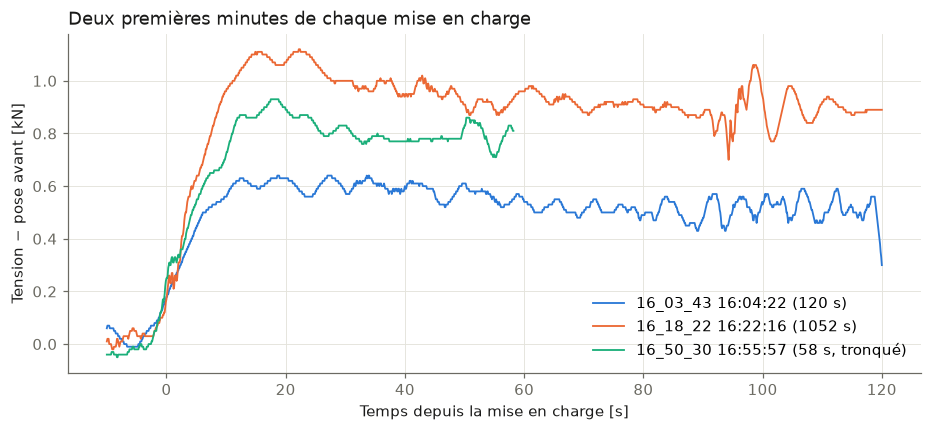

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
for _, e in events.iterrows():
    s = logs[e["fichier"]]
    seg = s[e["début"] - pd.Timedelta(seconds=10) : e["début"] + pd.Timedelta(seconds=120)]
    t = (seg.index - e["début"]).total_seconds()
    color = SERIES[list(logs).index(e["fichier"])]
    ax.plot(t, seg.values - e["base avant [kN]"], color=color,
            label=f"{e['fichier']} {e['début']:%H:%M:%S} ({e['durée [s]']} s{', tronqué' if e['tronqué'] else ''})")
ax.set_xlabel("Temps depuis la mise en charge [s]")
ax.set_ylabel("Tension − pose avant [kN]")
ax.set_title("Deux premières minutes de chaque mise en charge", loc="left", color=INK)
ax.legend(loc="lower right")
plt.show()

## Ce que ce notebook ne dit pas

- Il ne donne **pas la tension totale de la ligne** : un seul brin est instrumenté, et le partage
  50/50 entre les deux cordes est une hypothèse.
- Il ne sépare **pas** fluage, serrage des nœuds, glissement dans les appareils et mouvement des
  ancrages dans la perte de tension.
- Il ne relie **pas** encore les périodes en charge aux passagers, à leur masse ni aux heures notées
  sur le terrain, et ne contient **aucune retension** : elles ont été faites hors enregistrement.

Suite : [#68](https://github.com/fuzoh/simu-tyro/issues/68) pour les faits manquants,
[#67](https://github.com/fuzoh/simu-tyro/issues/67) pour la météo de l'après-midi,
[#69](https://github.com/fuzoh/simu-tyro/issues/69) pour décider ce que l'essai valide.